# **TUẦN 45 — ĐỐI CHIẾU UNIFASHION VỚI PAPER GỐC, BASELINE VÀ SOTA**

Nội dung thực hiện trong Tuần 44–45 tập trung đánh giá hiệu quả truy hồi ảnh của mô hình **UniFashion tích hợp Attention-Gated Fusion** trên tập validation của FashionIQ thông qua hai chỉ số Recall@10 và Recall@50, sử dụng checkpoint `best_monitor.pt` tại epoch 8. Quá trình thực nghiệm tận dụng checkpoint đã huấn luyện, không thực hiện huấn luyện lại, đồng thời kiểm tra tính nhất quán của dữ liệu, mã nguồn và cấu hình trước khi tiến hành đánh giá trên GPU. Đặc biệt, giao thức đánh giá được xác minh bằng cách đối chiếu mã SHA-256 giữa `preparation.json` và các tệp trong `evaluation_data`, trường hợp khác biệt chỉ do định dạng xuống dòng sẽ được khôi phục về định dạng phù hợp, hoặc toàn bộ 6.016 truy vấn sẽ được đối chiếu với dữ liệu baseline trước khi tạo manifest đánh giá riêng.

Các tệp nguồn lịch sử được giữ nguyên và quá trình đánh giá sẽ dừng nếu phát hiện nội dung dữ liệu không nhất quán. Sau khi hoàn tất, kết quả thực nghiệm được lưu tại `MyDrive/KHOALUAN/Tuần 45/Week45_Baseline_SOTA_Evidence/` để phục vụ việc so sánh với các baseline lịch sử và số liệu công bố trong paper UniFashion. Trong quá trình phân tích, kết quả từ paper được phân biệt rõ với kết quả thực nghiệm tự thực hiện, đồng thời không quy kết mức cải thiện cho riêng module Attention-Gated Fusion khi chưa có thí nghiệm ablation với điều kiện tương đương.


## **1 — Đồng bộ GitHub, Drive và nguồn huấn luyện**

In [ ]:
from pathlib import Path
import json, os, subprocess, sys, unicodedata, shutil
from google.colab import drive

drive.mount('/content/drive')
DRIVE = Path('/content/drive/MyDrive')
KHOALUAN = DRIVE / 'KHOALUAN'
def week_folder(number):
    found = [p for p in KHOALUAN.iterdir() if p.is_dir()
             and unicodedata.normalize('NFC', p.name) == f'Tuần {number}']
    if len(found) != 1:
        raise FileNotFoundError(f'Cần đúng 1 thư mục Tuần {number}; tìm thấy {found}')
    return found[0]

W41 = week_folder(41)
RUN41 = W41 / 'UniFashionResults_run2'
BEST, LAST = RUN41/'best_monitor.pt', RUN41/'last.pt'
BUNDLE = W41/'FashionIQ_prepared.zip'
PIN = W41/'UniFashionResults_run2.pinned_commit.txt'
ASSETS = DRIVE/'UniFashionAssets'
PROJECT = Path('/content/khoaluantotnghiep')
UPSTREAM = Path('/content/UniFashion-upstream')
WORK = Path('/content/week45_fashioniq')
OUTPUT = KHOALUAN/'Tuần 45'/'Week45_Baseline_SOTA_Evidence'
OUTPUT.mkdir(parents=True,exist_ok=True)
WORK.mkdir(parents=True,exist_ok=True)

def run(cmd,cwd=None):
    command=[str(x) for x in cmd]
    print('$', ' '.join(command), flush=True)
    subprocess.run(command,cwd=cwd,check=True)

# Luôn làm mới checkout main trên ĐĨA COLAB, kể cả sau lần chạy lỗi.
if not (PROJECT/'.git').is_dir():
    if PROJECT.exists():
        raise RuntimeError('PROJECT đã tồn tại nhưng không phải Git checkout: '+str(PROJECT))
    run(['git','clone','--branch','main','https://github.com/okok0814/khoaluantotnghiep.git',PROJECT])
else:
    run(['git','-C',PROJECT,'fetch','origin','main'])
    run(['git','-C',PROJECT,'checkout','--force','main'])
    run(['git','-C',PROJECT,'reset','--hard','origin/main'])
if not (UPSTREAM/'.git').is_dir():
    if UPSTREAM.exists(): raise RuntimeError('UPSTREAM tồn tại nhưng không phải Git clone')
    run(['git','clone','https://github.com/xiangyu-mm/UniFashion.git',UPSTREAM])

# Ghi lại bản baseline và code evaluator được commit trên main, rồi mới checkout mã lúc train
REF_COPY=Path('/content/week45_reference/week41_fashioniq_evaluation')
source=PROJECT/'logs/week41_fashioniq_evaluation'
if not source.is_dir():
    raise FileNotFoundError('Nhánh main thiếu logs/week41_fashioniq_evaluation; hãy kiểm tra git add/push.')
if REF_COPY.exists(): shutil.rmtree(REF_COPY) # chỉ xóa bản sao trong /content
REF_COPY.parent.mkdir(parents=True,exist_ok=True)
shutil.copytree(source,REF_COPY)
EVAL_HELPERS=['scripts/evaluate_unifashion_fashioniq.py',
              'src/fashioniq_evaluation.py','src/unifashion_tuning.py']
HELPERS_COPY=REF_COPY.parent/'evaluation_helpers'
if HELPERS_COPY.exists(): shutil.rmtree(HELPERS_COPY)
for rel in EVAL_HELPERS:
    original=PROJECT/rel
    if not original.is_file():raise FileNotFoundError('Nhánh main thiếu '+rel)
    backup=HELPERS_COPY/rel
    backup.parent.mkdir(parents=True,exist_ok=True)
    shutil.copy2(original,backup)

if not PIN.is_file():raise FileNotFoundError('Thiếu commit huấn luyện đã ghim: '+str(PIN))
pinned=PIN.read_text(encoding='utf-8').strip()
run(['git','-C',PROJECT,'checkout','--force','--quiet',pinned])
for rel in EVAL_HELPERS:
    dest=PROJECT/rel
    dest.parent.mkdir(parents=True,exist_ok=True)
    shutil.copy2(HELPERS_COPY/rel,dest)
BASELINE_CSV=REF_COPY/'comparison.csv'
required=[BEST,LAST,BUNDLE,RUN41/'environment.json',RUN41/'config.json',
          ASSETS/'eva_vit_g.pth',ASSETS/'pretrain/none_lora_0.pt',
          ASSETS/'download_manifest.json',ASSETS/'bert-base-uncased',
          REF_COPY/'preparation.json',BASELINE_CSV,
          REF_COPY/'baselines/fashionclip_additive.json',
          REF_COPY/'baselines/fashionclip_additive_per_query.csv',
          PROJECT/'scripts/evaluate_unifashion_fashioniq.py']
required += [REF_COPY/'evaluation_data'/x for x in
            ['queries.csv','gallery_captions.json',
             'split.dress.val.json','split.shirt.val.json','split.toptee.val.json']]
missing=[str(p) for p in required if not p.exists()]
if missing:raise FileNotFoundError('Thiếu tài nguyên đầu vào:\n'+'\n'.join(missing))
print('PASS | Git main và commit train đã ghim')
print('COMMIT TRAIN:',subprocess.check_output(['git','-C',str(PROJECT),'rev-parse','HEAD'],text=True).strip())
print('CHECKPOINT:',BEST)
print('ĐẦU RA:',OUTPUT)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
$ git -C /content/khoaluantotnghiep fetch origin main
$ git -C /content/khoaluantotnghiep checkout --force main
$ git -C /content/khoaluantotnghiep reset --hard origin/main
$ git -C /content/khoaluantotnghiep checkout --force --quiet 1d64db4b87ae87c2cf95d970d902908680360e4c
PASS | Git main và commit train đã ghim
COMMIT TRAIN: 1d64db4b87ae87c2cf95d970d902908680360e4c
CHECKPOINT: /content/drive/MyDrive/KHOALUAN/Tuần 41/UniFashionResults_run2/best_monitor.pt
ĐẦU RA: /content/drive/MyDrive/KHOALUAN/Tuần 45/Week45_Baseline_SOTA_Evidence


## **2 — Kiểm tra GPU, dữ liệu FashionIQ và tính toàn vẹn giao thức**

* Kiểm tra GPU trước khi cài gói, tránh tải lại thư viện nếu Colab chưa có GPU.

* Đối chiếu SHA mã nguồn và tài nguyên huấn luyện; giải nén `FashionIQ_prepared.zip`.

* Kiểm tra `queries.csv`, gallery và caption trước khi khởi chạy GPU. Chỉ sửa cách xuống dòng khi mã SHA khớp chính xác; nếu hash khác do cách ghi CSV, đối chiếu nội dung đủ 6.016 truy vấn với file baseline per-query. Ghi lại mọi điều chỉnh vào `protocol_reconciliation.json`.


In [ ]:
import hashlib, zipfile, shutil, time

# Kiểm tra GPU ngay từ đầu để đảm bảo môi trường sẵn sàng chạy mô hình.
# Nếu xảy ra lỗi, chương trình sẽ hiển thị nguyên nhân cụ thể để dễ kiểm tra và khắc phục.
probe=subprocess.run(['nvidia-smi'],text=True,capture_output=True)
if probe.returncode:
    print(probe.stderr or probe.stdout)
    raise RuntimeError('Colab không có NVIDIA GPU. Chọn Runtime > Change runtime type > GPU, sau đó chạy từ Mục 1.')
print('GPU NVIDIA được nhận diện:')
print('\n'.join(probe.stdout.splitlines()[:8]))

run([sys.executable,'-m','pip','install','-q','uv'])
UV=shutil.which('uv')
if not UV:raise RuntimeError('Không tìm thấy uv sau khi cài')
run([UV,'python','install','3.12'])
VENV=Path('/content/unifashion-py312')
PYTHON=VENV/'bin/python'
if not PYTHON.is_file():run([UV,'venv','--python','3.12',VENV])
run([UV,'pip','install','--python',PYTHON,
     '--index-url','https://download.pytorch.org/whl/cu124',
     '--extra-index-url','https://pypi.org/simple',
     'torch==2.6.0','torchvision==0.21.0'])
run([UV,'pip','install','--python',PYTHON,'-r',PROJECT/'requirements-unifashion.txt'])
check=subprocess.run([str(PYTHON),'-c',
    'import torch; print("PyTorch:",torch.__version__,"CUDA built:",torch.version.cuda,"CUDA available:",torch.cuda.is_available()); '+
    'assert torch.cuda.is_available(), "GPU không khả dụng trong Python 3.12"; '+
    'print("GPU:",torch.cuda.get_device_name(0))'],capture_output=True,text=True)
print(check.stdout)
if check.returncode:
    print(check.stderr)
    raise RuntimeError('PyTorch 3.12 chưa dùng được GPU; xem chi tiết lỗi ngay phía trên.')

def sha256(p):
    h=hashlib.sha256()
    with Path(p).open('rb') as stream:
        for chunk in iter(lambda:stream.read(8*1024*1024),b''):h.update(chunk)
    return h.hexdigest()

env=json.loads((RUN41/'environment.json').read_text(encoding='utf-8'))
different=[]
for name,digest in env['fingerprint']['code'].items():
    found=[x for x in (PROJECT/'src'/name,PROJECT/'scripts'/name) if x.is_file()]
    actual=sha256(found[0]) if len(found)==1 else None
    print(name,'MATCH' if actual==digest else 'DIFFERENT/MISSING')
    if actual!=digest:different.append(name)
if different:raise RuntimeError('Mã nguồn khác lần train: '+repr(different)+'. Không bỏ qua fingerprint.')
if sha256(ASSETS/'download_manifest.json')!=env['fingerprint']['assets_manifest']:
    raise RuntimeError('Asset manifest khác lần train; không thể bảo đảm tính tái lập.')

# Nếu file asset manifest có lưu thông tin phiên bản mã nguồn UniFashion gốc, cần kiểm tra trước khi chạy đánh giá trên GPU để đảm bảo sử dụng đúng phiên bản.
assets_manifest=json.loads((ASSETS/'download_manifest.json').read_text(encoding='utf-8'))
for record in assets_manifest.get('files',[]):
    rel=record.get('path','').replace('\\','/')
    if rel.startswith('third_party/UniFashion/src/') and record.get('sha256'):
        target=UPSTREAM/rel.removeprefix('third_party/UniFashion/')
        if not target.is_file():
            raise FileNotFoundError('Thiếu mã nguồn UniFashion được ghim: '+str(target))
        if sha256(target)!=record['sha256']:
            raw=target.read_bytes()
            normalized=raw.replace(b'\r\n',b'\n')
            if hashlib.sha256(normalized).hexdigest()!=record['sha256'] and \
               hashlib.sha256(normalized.replace(b'\n',b'\r\n')).hexdigest()!=record['sha256']:
                raise RuntimeError('Upstream code không đúng bản train: '+rel)

DATA=WORK/'data'
IMAGES=WORK/'images'
marker=WORK/'.bundle_source.json'
signature={'bytes':BUNDLE.stat().st_size,'mtime_ns':BUNDLE.stat().st_mtime_ns,'source':str(BUNDLE)}
ready=(marker.is_file() and json.loads(marker.read_text())==signature
       and (DATA/'data_audit.json').is_file() and (DATA/'images_manifest.json').is_file()
       and IMAGES.is_dir())
if not ready:
    print('Giải nén FashionIQ từ gói Tuần 41 vào /content/...')
    with zipfile.ZipFile(BUNDLE) as archive:
        for item in archive.infolist():
            dest=(WORK/item.filename).resolve()
            if not dest.is_relative_to(WORK.resolve()):raise ValueError('ZIP chứa đường dẫn không an toàn')
            if item.is_dir():
                dest.mkdir(parents=True,exist_ok=True)
                continue
            dest.parent.mkdir(parents=True,exist_ok=True)
            if dest.is_file() and dest.stat().st_size==item.file_size:continue
            tmp=dest.with_name(dest.name+'.partial')
            with archive.open(item) as src,tmp.open('wb') as dst:
                shutil.copyfileobj(src,dst,8*1024*1024)
            if tmp.stat().st_size!=item.file_size:
                raise RuntimeError('Giải nén thiếu '+item.filename)
            tmp.replace(dest)
    if not (DATA/'data_audit.json').is_file() or not IMAGES.is_dir():
        raise RuntimeError('FashionIQ_prepared.zip không có cấu trúc data/ và images/ được yêu cầu')
    marker.write_text(json.dumps(signature,indent=2),encoding='utf-8')
if sha256(DATA/'data_audit.json')!=env['fingerprint']['data_audit']:
    raise RuntimeError('data_audit.json khác lần train, không đánh giá sai dữ liệu.')
print('PASS | Dữ liệu train và asset đã xác minh')

# Thực hiện bước kiểm tra ban đầu (pre-flight) để đảm bảo các file dữ liệu,
# mã nguồn và checkpoint đầy đủ, chính xác trước khi tiến hành đánh giá trên GPU.
# Đồng thời, giữ nguyên thư mục REF_COPY chứa dữ liệu tham chiếu để phục vụ việc đối chiếu và xác minh kết quả.
from pathlib import Path
import copy
import hashlib
import json
import shutil


def _sha256(path):
    h = hashlib.sha256()
    with Path(path).open('rb') as stream:
        for part in iter(lambda: stream.read(8*1024*1024), b''):
            h.update(part)
    return h.hexdigest()


def _restore_recorded_eol(path, expected):
    """Chỉ điều chỉnh định dạng xuống dòng của file khi mã SHA-256 sau khi chuyển đổi khớp với mã đã lưu trước đó, nhằm đảm bảo nội dung dữ liệu không bị thay đổi"""
    content = path.read_bytes()
    canonical_lf = content.replace(b'\r\n', b'\n').replace(b'\r', b'\n')
    for variant in (canonical_lf, canonical_lf.replace(b'\n', b'\r\n')):
        if hashlib.sha256(variant).hexdigest() == expected:
            if variant != content:
                path.write_bytes(variant)
            return True
    return False


def _verify_queries_semantically(current_queries, historical_predictions):
    """Đối chiếu chính xác cấu trúc cột và toàn bộ 6.016 truy vấn với dữ liệu tham chiếu, đảm bảo không có sự khác biệt về nội dung"""
    import pandas as pd
    current = pd.read_csv(current_queries, dtype=str, keep_default_na=False)
    prior = pd.read_csv(historical_predictions, dtype=str, keep_default_na=False)
    cols = current.columns.tolist()
    required = {'category', 'candidate', 'target', 'text'}
    if not required.issubset(cols) or not set(cols).issubset(prior.columns):
        raise RuntimeError('Không đủ cột để so sánh đầy đủ query với baseline.')
    keys = ['category', 'candidate', 'target']
    if len(current) != 6016 or len(prior) != len(current):
        raise RuntimeError(f'Số query khác baseline 6.016: new={len(current)}, old={len(prior)}')
    if current.duplicated(keys).any() or prior.duplicated(keys).any():
        raise RuntimeError('Trùng khóa category/candidate/target; không đủ cơ sở so khớp.')
    a = current[cols].sort_values(keys).reset_index(drop=True)
    b = prior[cols].sort_values(keys).reset_index(drop=True)
    try:
        pd.testing.assert_frame_equal(a, b, check_dtype=False, check_like=False)
    except AssertionError as exc:
        raise RuntimeError('Nội dung query khác baseline: KHÔNG thay hash để bỏ qua.') from exc
    return {'queries': len(a), 'fields_verified': cols, 'all_rows_equal': True}


def prepare_verified_protocol(reference_root, work_root, report_file):
    """Trả về đường dẫn dữ liệu tạm và kết quả đối chiếu, đồng thời giữ nguyên bộ dữ liệu gốc để phục vụ kiểm tra khi cần thiết"""
    reference_root, work_root = Path(reference_root), Path(work_root)
    manifest_file = reference_root/'preparation.json'
    original = json.loads(manifest_file.read_text(encoding='utf-8'))
    if not isinstance(original.get('files'), dict) or not isinstance(original.get('protocol'), dict):
        raise RuntimeError('preparation.json thiếu SHA hoặc dấu vân tay protocol.')
    original_data = reference_root/'evaluation_data'
    result_file = reference_root/'baselines'/'fashionclip_additive.json'
    predictions_file = reference_root/'baselines'/'fashionclip_additive_per_query.csv'
    if not result_file.is_file():
        raise RuntimeError('Thiếu kết quả FashionCLIP baseline có metadata protocol: '+str(result_file))
    historic = json.loads(result_file.read_text(encoding='utf-8'))
    if historic.get('protocol') != original['protocol']:
        raise RuntimeError('Baseline và preparation.json KHÔNG cùng protocol lịch sử.')
    stage = work_root/'verified_fashioniq_reference'
    data = stage/'evaluation_data'
    stage.mkdir(parents=True, exist_ok=True)
    data.mkdir(parents=True, exist_ok=True)
    prep = copy.deepcopy(original)
    change_log = []
    for name, recorded_sha in original['files'].items():
        if '/' in name or '\\' in name or name in ('.','..'):
            raise RuntimeError('Tên file bất thường trong manifest: '+repr(name))
        source = original_data/name
        destination = data/name
        if not source.is_file():
            raise FileNotFoundError('Thiếu file gốc trong evaluation_data: '+str(source))
        # Mỗi lần chạy sẽ tạo lại bản sao dữ liệu từ nguồn gốc và chỉ thực hiện các điều chỉnh cần thiết trong thư mục tạm, không thay đổi dữ liệu ban đầu
        shutil.copy2(source, destination)
        current_sha = _sha256(destination)
        if current_sha == recorded_sha:
            change_log.append({'file': name, 'mode':'exact_sha256_match', 'sha256':current_sha})
            continue
        if _restore_recorded_eol(destination, recorded_sha):
            change_log.append({'file': name, 'mode':'restored_recorded_line_endings', 'sha256':_sha256(destination)})
            continue
        if name == 'queries.csv':
            if not predictions_file.is_file():
                raise RuntimeError('queries.csv khác SHA; thiếu baseline per-query để xác minh nội dung: '+str(predictions_file))
            semantic = _verify_queries_semantically(destination, predictions_file)
            new_sha = _sha256(destination)
            prep['files'][name] = new_sha
            prep['protocol']['queries_sha256'] = new_sha
            change_log.append({'file':name, 'mode':'all_6016_queries_semantically_equal_to_saved_baseline',
                               'recorded_sha256':recorded_sha, 'used_sha256':new_sha, **semantic})
        else:
            raise RuntimeError('Không thể xác minh '+name+': SHA hiện tại '+current_sha+
                               ' khác SHA gốc '+recorded_sha+'. KHÔNG tự sửa manifest.')
    # Tạo file manifest đánh giá riêng dựa trên dữ liệu đã được xác minh, phục vụ quá trình thực nghiệm và không thay thế manifest gốc của tác giả
    prep['week45_protocol_reconciliation'] = {'baseline_preparation_untouched':str(manifest_file),
        'methods':{item['file']: item['mode'] for item in change_log}}
    (stage/'preparation.json').write_text(json.dumps(prep, ensure_ascii=False, indent=2), encoding='utf-8')
    # Xác minh trực tiếp file manifest được script đánh giá sử dụng, đảm bảo thông tin kiểm tra ban đầu nhất quán với dữ liệu thực tế khi chạy mô hình
    for name, expected in prep['files'].items():
        if _sha256(data/name) != expected:
            raise RuntimeError('Lỗi nội bộ: checksum file staging chưa đúng: '+name)
    if prep['protocol']['queries_sha256'] != _sha256(data/'queries.csv'):
        raise RuntimeError('Lỗi nội bộ: protocol.sha256 khác queries.csv.')
    # Giữ nguyên các thông số của giao thức đánh giá ngoài dữ liệu truy vấn, đặc biệt là mã SHA-256 của gallery, nhằm đảm bảo tính nhất quán và công bằng khi so sánh kết quả
    for field, value in original['protocol'].items():
        if field != 'queries_sha256' and prep['protocol'].get(field) != value:
            raise RuntimeError('Protocol thay đổi không được phép: '+field)
    report = {'status':'validated', 'reference_source':str(reference_root), 'verified_stage':str(stage),
              'historic_protocol_queries_sha256':original['protocol']['queries_sha256'],
              'evaluated_protocol_queries_sha256':prep['protocol']['queries_sha256'],
              'baseline_method':'fashionclip_additive', 'original_preparation_not_modified':True,
              'details':change_log}
    report_file = Path(report_file)
    report_file.parent.mkdir(parents=True, exist_ok=True)
    report_file.write_text(json.dumps(report, ensure_ascii=False, indent=2), encoding='utf-8')
    print('PASS | Preflight FashionIQ SHA256 + protocol')
    for item in change_log:
        print('  ',item['file'],':', item['mode'])
    return stage, report


EVAL_ROOT, PROTOCOL_REPORT=prepare_verified_protocol(
    REF_COPY, WORK, OUTPUT/'protocol_reconciliation.json')
EVAL_DATA=EVAL_ROOT/'evaluation_data'
# Kiểm tra tính hợp lệ của dữ liệu bằng hàm protocol() trong chương trình đánh giá, sử dụng môi trường Python 3.12 để đảm bảo sự nhất quán trước khi chạy mô hình.
probe_code=(
    'from src.fashioniq_evaluation import protocol; '
    'from pathlib import Path; import json,sys; '
    'q,g,f=protocol(Path(sys.argv[1])); '
    'p=json.loads((Path(sys.argv[1]).parent/"preparation.json").read_text()); '
    'assert f==p["protocol"], "Protocol fingerprint mismatch"; '
    'print("PASS | Validation queries",len(q),"| gallery",{k:len(v) for k,v in g.items()})'
)
res=subprocess.run([str(PYTHON),'-c',probe_code,str(EVAL_DATA)],cwd=str(PROJECT),
                   capture_output=True,text=True)
print(res.stdout)
if res.returncode:
    print(res.stderr)
    raise RuntimeError('Bộ truy vấn không qua được protocol() của evaluator. GPU chưa chạy.')
print('PASS | Mọi file evaluation_data đã qua bước xác minh trước GPU')

GPU NVIDIA được nhận diện:
Mon Nov  9 08:44:07 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
$ /usr/bin/python3 -m pip install -q uv
$ /usr/local/bin/uv python install 3.12
$ /usr/local/bin/uv pip install --python /content/unifashion-py312/bin/python --index-url https://download.pytorch.org/whl/cu124 --extra-index-url https://pypi.org/simple torch==2.6.0 torchvision==0.21.0
$ /usr/local/

## **3 — Kiểm tra `best_monitor.pt` và tạo snapshot phục vụ đánh giá**

Sử dụng trọng số mô hình từ checkpoint `best_monitor.pt` tại epoch 8 để thực hiện đánh giá truy hồi ảnh. Do script đánh giá cũ yêu cầu thông tin lịch sử huấn luyện, notebook tạo một bản checkpoint riêng (snapshot) bằng cách giữ nguyên trọng số mô hình và bổ sung lịch sử từ `last.pt` đến epoch 8. Trước khi sử dụng, chương trình kiểm tra thông tin epoch, monitor loss, cấu hình huấn luyện và 8 tham số Attention-Gated Fusion để đảm bảo tính nhất quán. Nếu snapshot đã tồn tại và khớp với checkpoint gốc cùng thông tin xác minh, chương trình sẽ sử dụng lại mà không tạo mới.

In [ ]:
SNAPSHOT = WORK / 'best_monitor_eval_snapshot.pt'
AUDIT = OUTPUT / 'checkpoint_audit.json'
BUILD_SCRIPT = WORK / 'make_best_eval_snapshot.py'
BUILD_SCRIPT.write_text(r"""
import argparse, hashlib, json
from pathlib import Path
import torch

def digest(path):
    h=hashlib.sha256()
    with open(path,'rb') as f:
        for block in iter(lambda:f.read(8*1024*1024),b''):h.update(block)
    return h.hexdigest()

p=argparse.ArgumentParser()
for n in ('last','best','snapshot','audit'): p.add_argument('--'+n,required=True,type=Path)
a=p.parse_args()
last=torch.load(a.last,map_location='cpu',weights_only=True,mmap=True)
best=torch.load(a.best,map_location='cpu',weights_only=True,mmap=True)
assert last['cursor']==[10,0] and len(last['epochs'])==10 and len(last['history'])==90000
assert int(best['epoch']) in range(1,11)
epoch=int(best['epoch'])
row=last['epochs'][epoch-1]
assert int(row['epoch'])==epoch and abs(float(row['monitor_loss'])-float(best['monitor_loss']))<1e-8
assert last['config']==best['config']
assert set(last['model'])==set(best['model'])
fusion=[k for k in best['model'] if k.startswith('attention_fusion.')]
assert len(fusion)==8, ('Không đủ 8 tham số fusion',fusion)
assert best.get('selection')=='fixed monitor loss, NOT Recall@K'
step=int(row['step'])
history=last['history'][:step]
assert len(history)==step and history[-1]['step']==step
assert last['epochs'][:epoch][-1]['step']==step
# Chỉ metadata epoch tương ứng; trọng số từ best, không từ last.
snapshot={'model':best['model'],'config':best['config'],
          'fingerprint':last['fingerprint'], 'history':history,
          'epochs':last['epochs'][:epoch], 'cursor':[epoch,0]}
torch.save(snapshot,a.snapshot)
report={'variant':'UniFashion + Attention-Gated Fusion',
        'weight_origin':'best_monitor.pt','epoch':epoch,'optimizer_step_at_epoch':step,
        'monitor_loss':float(best['monitor_loss']),
        'best_original_sha256':digest(a.best),'last_original_sha256':digest(a.last),
        'evaluation_snapshot_sha256':digest(a.snapshot),
        'fusion_parameter_keys':fusion,
        'source_signature': {'best_bytes':a.best.stat().st_size,
                             'best_mtime_ns':a.best.stat().st_mtime_ns,
                             'last_bytes':a.last.stat().st_size,
                             'last_mtime_ns':a.last.stat().st_mtime_ns},
        'snapshot_note':'Được tạo chỉ để tái sử dụng script evaluator; weights=best_monitor, history=last truncated to best epoch. Không phải checkpoint train mới.'}
a.audit.write_text(json.dumps(report,ensure_ascii=False,indent=2),encoding='utf-8')
print(json.dumps({k:report[k] for k in ['weight_origin','epoch','optimizer_step_at_epoch','monitor_loss','fusion_parameter_keys']},ensure_ascii=False,indent=2))
""",encoding='utf-8')

# Tái sử dụng snapshot nếu tất cả nguồn và SHA vẫn giống bản đã kiểm toán.
source_signature={'best_bytes':BEST.stat().st_size,'best_mtime_ns':BEST.stat().st_mtime_ns,
                  'last_bytes':LAST.stat().st_size,'last_mtime_ns':LAST.stat().st_mtime_ns}
reuse=False
if SNAPSHOT.is_file() and AUDIT.is_file():
    prev=json.loads(AUDIT.read_text(encoding='utf-8'))
    reuse=(prev.get('source_signature')==source_signature and
           prev.get('evaluation_snapshot_sha256')==sha256(SNAPSHOT))
if reuse:
    print('PASS | Snapshot đã xác minh từ lượt trước, không tạo lại.')
else:
    run([PYTHON, BUILD_SCRIPT, '--last', LAST, '--best', BEST,
         '--snapshot', SNAPSHOT, '--audit', AUDIT])
    if json.loads(AUDIT.read_text(encoding='utf-8'))['evaluation_snapshot_sha256']!=sha256(SNAPSHOT):
        raise RuntimeError('Snapshot sau khi tạo không khớp SHA-256')
print('Snapshot chỉ dùng inference:', SNAPSHOT)
print('Minh chứng:', AUDIT)

PASS | Snapshot đã xác minh từ lượt trước, không tạo lại.
Snapshot chỉ dùng inference: /content/week45_fashioniq/best_monitor_eval_snapshot.pt
Minh chứng: /content/drive/MyDrive/KHOALUAN/Tuần 45/Week45_Baseline_SOTA_Evidence/checkpoint_audit.json


## **4 — Đánh giá Recall@10/@50 trên FashionIQ validation**

Sau khi xác minh dữ liệu ở Mục 2 và snapshot mô hình ở Mục 3, notebook sử dụng script có sẵn để đánh giá khả năng truy hồi ảnh trên FashionIQ và lưu lại nhật ký thực thi. Nếu đã có kết quả đánh giá hoàn chỉnh từ trước, chương trình sẽ kiểm tra checkpoint và giao thức đánh giá để đảm bảo trùng khớp trước khi sử dụng lại, giúp tránh chạy GPU không cần thiết. Các kết quả chưa hoàn tất hoặc không hợp lệ sẽ không được sử dụng để tính toán và báo cáo chỉ số Recall@K.

In [12]:
import datetime, time
EVAL_OUT = OUTPUT / 'fusion_fashioniq_results'
expected_sha = json.loads(AUDIT.read_text(encoding='utf-8'))['evaluation_snapshot_sha256']
expected_protocol = json.loads((EVAL_ROOT/'preparation.json').read_text(encoding='utf-8'))['protocol']
methods=('unifashion_image_score','unifashion_image_caption_score')
completed = False
if (EVAL_OUT/'status.json').is_file():
    try:
        status=json.loads((EVAL_OUT/'status.json').read_text(encoding='utf-8'))
        completed=(status.get('status')=='evaluation_completed'
                   and status.get('retrieval_evaluated') is True
                   and status.get('checkpoint_sha256')==expected_sha
                   and all((EVAL_OUT/(m+'.json')).is_file() for m in methods))
        if completed:
            for m in methods:
                result=json.loads((EVAL_OUT/(m+'.json')).read_text(encoding='utf-8'))
                if (result.get('protocol')!=expected_protocol or
                    result.get('provenance',{}).get('checkpoint_sha256')!=expected_sha):
                    completed=False
                    break
    except (OSError,ValueError,KeyError) as exc:
        print('Kết quả cũ không hợp lệ, sẽ chạy lại:',exc)
        completed=False
if not completed and EVAL_OUT.exists():
    stamp = datetime.datetime.now().strftime('%Y%m%dT%H%M%S_%f')
    archived = EVAL_OUT.with_name(EVAL_OUT.name+'_interrupted_'+stamp)
    EVAL_OUT.rename(archived)
    print('Giữ nguyên kết quả chưa hoàn tất:', archived)
if not completed:
    report=json.loads((OUTPUT/'protocol_reconciliation.json').read_text(encoding='utf-8'))
    assert report['status']=='validated' and report['verified_stage']==str(EVAL_ROOT)
    print('PASS | Dữ liệu đã qua preflight; bắt đầu GPU inference')
    command=[PYTHON,'-B','-u',PROJECT/'scripts/evaluate_unifashion_fashioniq.py',
             '--checkpoint',SNAPSHOT, '--eval-data',EVAL_DATA,
             '--data-dir',DATA,'--images-dir',IMAGES,
             '--output',EVAL_OUT,'--batch-size','2',
             '--upstream',UPSTREAM,'--assets',ASSETS]
    started=time.time()
    proc=subprocess.Popen([str(x) for x in command],cwd=str(PROJECT),
                          stdout=subprocess.PIPE,stderr=subprocess.STDOUT,
                          text=True,bufsize=1)
    with (OUTPUT/'evaluation_live.log').open('a',encoding='utf-8') as log:
        for line in proc.stdout:
            print(line,end='',flush=True)
            log.write(line);log.flush()
    rc=proc.wait()
    print('Return code:',rc,'| seconds:',round(time.time()-started))
    if rc: raise RuntimeError('Đánh giá thất bại; xem '+str(OUTPUT/'evaluation_live.log'))
else:
    print('Đã có kết quả FashionIQ hoàn tất với cùng snapshot, không chạy lại.')
result_status=json.loads((EVAL_OUT/'status.json').read_text())
assert result_status['status']=='evaluation_completed' and result_status['retrieval_evaluated']
assert result_status['checkpoint_sha256']==expected_sha
print('PASS | Queries:',result_status['queries'],'| Checkpoint epoch:',json.loads(AUDIT.read_text())['epoch'])

Giữ nguyên kết quả chưa hoàn tất: /content/drive/MyDrive/KHOALUAN/Tuần 45/Week45_Baseline_SOTA_Evidence/fusion_fashioniq_results_interrupted_20261109T084418_466105
PASS | Dữ liệu đã qua preflight; bắt đầu GPU inference
Reading and hashing the checkpoint snapshot...
Verifying 15415 validation images...
Verifying the frozen EVA-G checkpoint...
WARNING | EVA-G manifest has no SHA-256. File size matches, but training-time weight identity is not independently verified.
EVA-G actual SHA-256: 99d2bb36c6b52c94fe6e2e12373afb27de57ae81378c3d8c53bf0e83b0f4275f
Snapshot progress: {"optimizer_steps": 72000, "completed_epochs": 8, "next_epoch_one_based": 9, "completed_batches_in_current_epoch": 0}
/content/unifashion-py312/lib/python3.12/site-packages/transformers/utils/generic.py:441: FutureWarning: `torch.utils._pytree._register_pytree_node` is deprecated. Please use `torch.utils._pytree.register_pytree_node` instead.
  _torch_pytree._register_pytree_node(
/content/unifashion-py312/lib/python3.12/

## **5 — Kết quả Recall@K và baseline lịch sử**

Đọc số liệu thật vừa tính và đối chiếu với FashionCLIP và UniFashion trước đây, ghi rõ các checkpoint lịch sử khác lần huấn luyện fusion, nên không tự nhận đây là ablation kiểm soát cùng điều kiện.

KẾT QUẢ MACRO RECALL (phần trăm):
                                             method  Recall@10  Recall@50                           comparison_level
UniFashion + Attention-Gated Fusion / image+caption     64.285     80.739        Đo mới / cùng protocol trong Cell 4
        UniFashion + Attention-Gated Fusion / image     45.322     68.596        Đo mới / cùng protocol trong Cell 4
                               fashionclip_additive     23.622     41.537 Tham khảo lịch sử; chưa là ablation fusion
                             fashionclip_image_only      7.607     16.922 Tham khảo lịch sử; chưa là ablation fusion
                              fashionclip_text_only     27.780     47.101 Tham khảo lịch sử; chưa là ablation fusion
                     unifashion_image_caption_score     57.076     75.431 Tham khảo lịch sử; chưa là ablation fusion
                             unifashion_image_score     36.211     60.408 Tham khảo lịch sử; chưa là ablation fusion

FUSION THEO TỪNG NHÓM:
catego

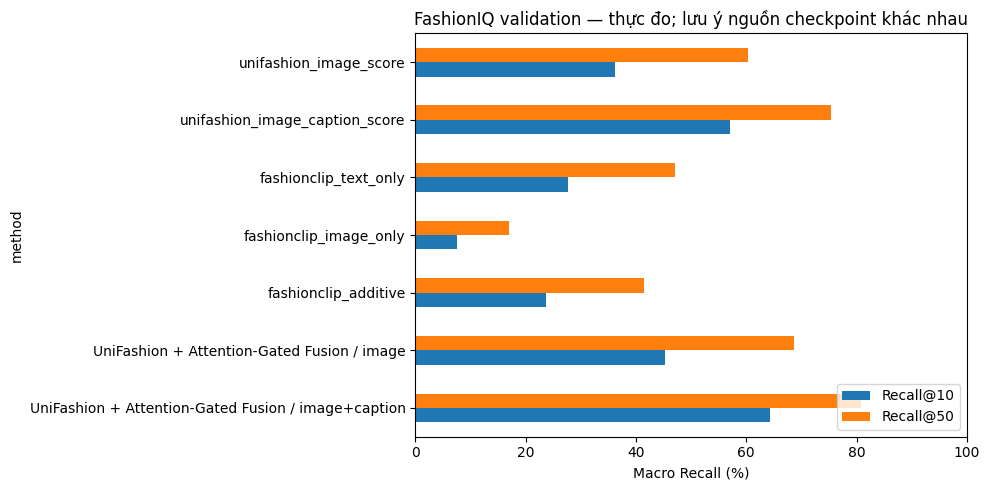

Đã lưu: /content/drive/MyDrive/KHOALUAN/Tuần 45/Week45_Baseline_SOTA_Evidence/measured_recall_chart.png


In [13]:
import pandas as pd
import matplotlib.pyplot as plt

variant='unifashion_image_caption_score'
fusion_json=json.loads((EVAL_OUT/(variant+'.json')).read_text(encoding='utf-8'))
visual_json=json.loads((EVAL_OUT/'unifashion_image_score.json').read_text(encoding='utf-8'))
assert fusion_json['protocol']==visual_json['protocol']
assert fusion_json['provenance']['checkpoint_sha256']==expected_sha
fusion=pd.DataFrame(fusion_json['summary'])
visual=pd.DataFrame(visual_json['summary'])
baselines=pd.read_csv(BASELINE_CSV)
assert fusion_json['protocol']==json.loads((EVAL_ROOT/'preparation.json').read_text(encoding='utf-8'))['protocol']
assert json.loads((OUTPUT/'protocol_reconciliation.json').read_text(encoding='utf-8'))['status']=='validated'
assert {'method','category','Recall@10','Recall@50'}.issubset(baselines.columns)

rows=[]
for method,frame,origin in [
    ('UniFashion + Attention-Gated Fusion / image+caption',fusion,'Đo mới: best_monitor.pt epoch 8'),
    ('UniFashion + Attention-Gated Fusion / image',visual,'Đo mới: best_monitor.pt epoch 8'),
]:
    for r in frame.to_dict('records'):
        rows.append({'method':method,'category':r['category'],
                     'Recall@10':r['Recall@10'],'Recall@50':r['Recall@50'],
                     'source':origin,'comparison_level':'Đo mới / cùng protocol trong Cell 4'})
for r in baselines.to_dict('records'):
    rows.append({'method':r['method'],'category':r['category'],
                 'Recall@10':r['Recall@10'],'Recall@50':r['Recall@50'],
                 'source':'Kết quả thực đo lịch sử Tuần 41, checkpoint riêng (có thể thuộc bước 29500)',
                 'comparison_level':'Tham khảo lịch sử; chưa là ablation fusion'})
measured=pd.DataFrame(rows)
measured.to_csv(OUTPUT/'measured_recall_comparison.csv',index=False)
macro=measured[measured.category=='MACRO'].copy()
print('KẾT QUẢ MACRO RECALL (phần trăm)')
print(macro[['method','Recall@10','Recall@50','comparison_level']].round(3).to_string(index=False))
print('\nFUSION THEO TỪNG NHÓM:')
print(fusion[['category','queries','Recall@10','Recall@50']].round(3).to_string(index=False))

fig,ax=plt.subplots(figsize=(10,5))
macro.set_index('method')[['Recall@10','Recall@50']].plot(kind='barh',ax=ax)
ax.set_xlabel('Macro Recall (%)');ax.set_xlim(0,100)
ax.set_title('FashionIQ validation — thực đo; lưu ý nguồn checkpoint khác nhau')
ax.legend(loc='lower right');fig.tight_layout()
chart=OUTPUT/'measured_recall_chart.png'
fig.savefig(chart,dpi=160,bbox_inches='tight')
plt.show();plt.close(fig)
print('Đã lưu ',chart)

## **6 — Đối chiếu paper UniFashion 2024 và các phương pháp công bố**
Sử dụng số liệu từ Bảng 4, trang 8 của bài báo [UniFashion (arXiv:2408.11305)](https://arxiv.org/abs/2408.11305) để đối chiếu với kết quả thực nghiệm của mô hình. Đây là các kết quả do tác giả công bố, không phải kết quả được thực hiện trực tiếp trong quá trình đánh giá của đề tài. Đồng thời, các phương pháp được trình bày chỉ mang tính chất tham khảo và so sánh, không được xem là những phương pháp SOTA mới nhất tại thời điểm năm 2026.

In [14]:
# Số liệu đọc trực tiếp từ Table 4, trang 8, paper UniFashion.
published=[
    ('CASE',48.79,70.68),
    ('FAME-ViL',46.84,69.75),
    ('SPRC',54.92,74.97),
    ('UniFashion (paper gốc)',58.93,76.93),
]
paper=pd.DataFrame(published,columns=['method','Recall@10','Recall@50'])
paper['dataset']='FashionIQ validation'
paper['source']='UniFashion (2024), Table 4, page 8; https://arxiv.org/abs/2408.11305'
paper['type']='Công bố, không tự chạy'
paper.to_csv(OUTPUT/'paper_published_results.csv',index=False)

fusion_macro=fusion.loc[fusion.category=='MACRO'].iloc[0]
print('ĐO THỰC TẾ FUSION:')
print(f"Macro R@10={fusion_macro['Recall@10']:.3f}%; R@50={fusion_macro['Recall@50']:.3f}%")
print('\nSỐ LIỆU PAPER GỐC:')
print(paper[['method','Recall@10','Recall@50']].to_string(index=False))
print('\nLƯU Ý: Các giá trị công bố chỉ là mốc tham khảo; điều kiện train/scoring có thể khác.')
print('Không kết luận thắng SOTA hay cải thiện do fusion từ bảng công bố một mình')

ĐO THỰC TẾ FUSION:
Macro R@10=64.285%; R@50=80.739%

SỐ LIỆU PAPER GỐC:
                method  Recall@10  Recall@50
                  CASE      48.79      70.68
              FAME-ViL      46.84      69.75
                  SPRC      54.92      74.97
UniFashion (paper gốc)      58.93      76.93

LƯU Ý: Các giá trị công bố chỉ là mốc tham khảo; điều kiện train/scoring có thể khác.
Không kết luận thắng SOTA hay cải thiện do fusion từ bảng công bố một mình.


## **7 — Lưu kết quả và minh chứng thực nghiệm**

In [ ]:
audit=json.loads(AUDIT.read_text(encoding='utf-8'))
status=json.loads((EVAL_OUT/'status.json').read_text(encoding='utf-8'))
summary={
    'status':'evaluation_completed',
    'dataset':'FashionIQ validation',
    'queries':int(status['queries']),
    'checkpoint_origin':str(BEST),
    'checkpoint_epoch':audit['epoch'],
    'checkpoint_sha256':audit['best_original_sha256'],
    'evaluation_snapshot_sha256':audit['evaluation_snapshot_sha256'],
    'fusion_macro_recall_10':float(fusion_macro['Recall@10']),
    'fusion_macro_recall_50':float(fusion_macro['Recall@50']),
    'reproduction_note':'Paper results are published references, not same-run reproduction.',
    'protocol_reconciliation':str(OUTPUT/'protocol_reconciliation.json'),
    'ablation_verified':False,
    'sota_current_verified':False,
    'no_fusion_same_run':'Chưa có đánh giá baseline cùng điều kiện được kiểm chứng.',
}
(OUTPUT/'week45_summary.json').write_text(json.dumps(summary,ensure_ascii=False,indent=2),encoding='utf-8')
report=[
    '# Đối chiếu UniFashion, baseline và paper gốc — tổng hợp Tuần 44–45',
    '',f'- Trạng thái: {summary["status"]}.',
    f'- Mô hình đề xuất: `best_monitor.pt`, epoch {audit["epoch"]}, có {len(audit["fusion_parameter_keys"])} khóa Attention-Gated Fusion.',
    f'- FashionIQ validation: {summary["queries"]} queries.',
    f'- Macro Recall@10: **{summary["fusion_macro_recall_10"]:.3f}%**.',
    f'- Macro Recall@50: **{summary["fusion_macro_recall_50"]:.3f}%**.',
    '- Bảng baseline lịch sử: `measured_recall_comparison.csv`. Đây chưa phải ablation cùng điều kiện.',
    '- Bảng số liệu công bố: `paper_published_results.csv` (UniFashion 2024, Table 4, p.8).',
    '- Giao thức FashionIQ: xem `protocol_reconciliation.json`; mọi khác biệt định dạng đều đã được kiểm chứng và ghi lại.',
    '- Không dùng monitor loss thay Recall@K.',
    '- Chưa đủ cơ sở để khẳng định mức đóng góp riêng của fusion nếu thiếu baseline UniFashion không fusion trong cùng điều kiện.',
    '- Chưa xác minh bảng xếp hạng SOTA hiện hành hoặc kết quả MAPNet/SPN4CIR, nên không đưa số liệu giả.',
    '', '## Minh chứng notebook',
    '1. Cell mã Mục 3: checkpoint audit (epoch, tham số fusion, SHA-256).',
    '2. Cell mã Mục 4: log đánh giá hoàn tất và số lượng query.',
    '3. Cell mã Mục 5: Recall@K, biểu đồ so sánh.',
    '4. Cell mã Mục 6: bảng số liệu công bố và nguồn paper.',
]
(OUTPUT/'week45_comparison_report.md').write_text('\n'.join(report)+'\n',encoding='utf-8')
print('HOÀN TẤT MINH CHỨNG TUẦN 45:')
for name in ('checkpoint_audit.json','protocol_reconciliation.json','measured_recall_comparison.csv','measured_recall_chart.png',
             'paper_published_results.csv','week45_summary.json','week45_comparison_report.md'):
    p=OUTPUT/name
    assert p.is_file() and p.stat().st_size>0, p
    print('-',p.name)
print('\nCHÚ Ý: Báo cáo Word sẽ trích số từ các file trên, không suy đoán trước khi chạy.')

HOÀN TẤT MINH CHỨNG TUẦN 45:
- checkpoint_audit.json
- protocol_reconciliation.json
- measured_recall_comparison.csv
- measured_recall_chart.png
- paper_published_results.csv
- week45_summary.json
- week45_comparison_report.md

CHÚ Ý: Báo cáo Word sẽ trích số từ các file trên, không suy đoán trước khi chạy.
